# 1. A Connection Budget

> **Overview.** With a fixed budget of connections, the LTUs' first inputs, mostly wrong, fill it. Can pruning free
> the room to add the LTUs a sparse target network needs?

**Setup.** The one-layer method of `../step_by_step/4_parent_weights.ipynb`, on a target network of 16 LTUs, each
reading 10 of 1000 inputs, with a budget of 320 connections from the inputs to the LTUs: room for 2 LTUs wired like
each target LTU. Growth connects an input only while the budget has room, and search, after removing the weakest LTUs,
adds new ones as long as the budget has room for their first inputs. With and without pruning: every 10k steps, just
before search, each LTU stops reading every input whose weight changed sign since the last pruning. A wrong input's
weight jitters around zero and sooner or later changes sign; a right one's keeps its sign. Output noise of std 0.1 or
1. 5 seeds; 500k steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 16                       # target LTUs
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # observation noise on each output: the lowest RMSE possible
BUDGET = 2 * N_TARGETS * N_SOURCES   # connections from the inputs to the LTUs: room for 2 LTUs like each target LTU

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
SLOTS = 48                           # most LTUs at once (never reached)
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs removed at each search step, those with the smallest sum of |output weights|

# --- Experiment ---
NUM_STEPS = 500_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps, each just after a pruning

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # Each target LTU reads N_SOURCES inputs and each output OUTPUT_FAN_IN target LTUs, all drawn at random, with
    # random +-1 weights (the outputs' scaled to unit variance).
    read_key, w_key, out_key, out_w_key = jax.random.split(key, 4)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def sample(target, noise_std, key):
    # One input and its targets, with N(0, noise_std^2) noise.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    clean = target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0)
    return x, clean + noise_std * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

The learner of `../step_by_step/4_parent_weights.ipynb`, with `prune`, in `SLOTS` slots of which those in `alive` hold
an LTU, and with the budget: `grow` connects an input only while the budget has room, and `search` removes the weakest
LTUs, then fills the room left with new ones.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (SLOTS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (SLOTS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + SLOTS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    alive: jax.Array            # (SLOTS,): which slots hold an LTU
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, SLOTS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (SLOTS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection


def init_net(key, target, units):
    # `units` LTUs, each pair wired like one target LTU in turn: reading its inputs and the bias, with LeCun uniform
    # weights at step-size FAST_STEP_SIZE; their shadow weights +1 and -1, on a random output that reads that target
    # LTU. Every other weight 0.
    w_key, out_key = jax.random.split(key)
    alive = jnp.arange(SLOTS) < units
    assigned = jnp.arange(SLOTS) // 2 % N_TARGETS
    reads = jnp.append(target.w[assigned] != 0, jnp.ones((SLOTS, 1), bool), axis=1) & alive[:, None]
    readers = target.out[:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(SLOTS) % 2 == 0, 1.0, -1.0) * alive
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / N_SOURCES) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + SLOTS + 1))}
    opt = OPTIMIZER.init(w)
    beta = jnp.where(reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), opt.beta['hidden'])
    stats = Stats(jnp.full(SLOTS, 0.5), jnp.zeros(SLOTS), jnp.zeros(SLOTS))
    return Net(w, reads, alive, opt._replace(beta={**opt.beta, 'hidden': beta}), stats, shadow,
               jnp.zeros((SLOTS, N_INPUTS)))


def used(net):
    # The connections from the inputs to the LTUs, which count against the budget.
    return net.reads[:, :-1].sum()


def rewire(net, key, replaced, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on a random output, its parent.
    # It reads FAN_IN inputs and the bias, the inputs drawn without replacement with probability proportional to the
    # square of the parent's linear weight on each if parent, uniformly otherwise (Gumbel top-k),
    # with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear weights if signs, at
    # step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(SLOTS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.randint(out_key, (SLOTS,), 0, N_OUTPUTS)
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((SLOTS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((SLOTS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((SLOTS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and its prediction for this sample, made before learning from it, and adds dL/dz * x_i to
    # each LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.alive
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                                       jax.lax.stop_gradient(prediction))

    (loss, (source, h, mean, prediction)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(SLOTS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x), prediction


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums, while the budget has
    # room (the lowest slots first).
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & net.alive
    grows = grows & (jnp.cumsum(grows) <= BUDGET - used(net))
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def prune(net, signs):
    # Each LTU stops reading every input whose weight's sign differs from `signs`, its sign at the last pruning (0 for
    # inputs read since); the bias stays. The cut connections' weights and Autostep state are reset.
    w = net.w['hidden'][:, :-1]
    cut = jnp.zeros_like(net.reads).at[:, :-1].set(net.reads[:, :-1] & (signs != 0) & (jnp.sign(w) != signs))
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    opt = net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v))
    return net._replace(w=zero(net.w), reads=net.reads & ~cut, opt=opt)


def search(net, key):
    # The REPLACED LTUs with the smallest sum of |output weights| are removed; then new LTUs fill empty slots while the
    # budget has room for their FAN_IN inputs. Returns the network and the slots removed or filled.
    strength = jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
    removed = net.alive & (jnp.argsort(jnp.argsort(jnp.where(net.alive, strength, jnp.inf))) < REPLACED)
    alive = net.alive & ~removed
    room = BUDGET - (net.reads[:, :-1] & alive[:, None]).sum()
    new = ~alive & (jnp.cumsum(~alive) <= room // FAN_IN)
    net = rewire(net, key, removed | new, True, True)
    alive = alive | new
    return net._replace(alive=alive, reads=net.reads & alive[:, None], shadow=net.shadow * alive), removed | new

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, noise_std, searched, prunes):
    # NUM_STEPS online network-Autostep steps on samples from `target` with noise_std. If searched, the LTUs start as
    # new LTUs reading random inputs with random signs (their parents have no weights yet); each then grows every WINDOW
    # steps, and every PERIOD steps the LTUs are pruned (if prunes), then searched, and the signs of the weights
    # recorded (0 for the new LTUs'). Returns each window's mean squared error and the number of LTUs at its end.
    def window(carry, inputs):
        net, signs = carry
        index, key = inputs
        wire_key, key = jax.random.split(key)
        net = pick((index == 0) & searched, rewire(net, wire_key, net.alive, False, False), net)

        def step(net, key):
            x, y = sample(target, noise_std, key)
            net, prediction = learn(net, x, y)
            return net, jnp.mean((prediction - y) ** 2)

        net, mse = jax.lax.scan(step, net, jax.random.split(key, WINDOW))
        net = pick(searched, grow(net), net)
        due = searched & ((index + 1) * WINDOW % PERIOD == 0)
        net = pick(due & prunes, prune(net, signs), net)
        searched_net, new = search(net, jax.random.fold_in(wire_key, 1))
        net = pick(due, searched_net, net)
        signs = jnp.where(due, jnp.sign(net.w['hidden'][:, :-1]) * net.reads[:, :-1] * ~new[:, None], signs)
        return (net, signs), (mse.mean(), net.alive.sum())

    n = NUM_STEPS // WINDOW
    start = (net, jnp.zeros_like(net.w['hidden'][:, :-1]))
    return jax.lax.scan(window, start, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (units, searched, prunes) of configs, starting with `units` LTUs, at every noise std of NOISE_STDS and on
    # N_SEEDS seeds, vmapped together; seed s gives every run the same target network and samples. Returns
    # {(config, noise std): the RMSE of each window, shaped (seed, window)} and the same for the number of LTUs.
    runs = [(c, n) for c in configs for n in NOISE_STDS]
    noise, units, searched, prunes, seed = (jnp.array(v) for v in zip(*[(n, *c, s) for c, n in runs
                                                                        for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(init_net)(keys(0), targets, units)
    mse, ltus = (np.asarray(a).reshape(len(runs), N_SEEDS, -1)
                 for a in jax.jit(jax.vmap(train))(nets, keys(1), targets, noise, searched, prunes))
    return dict(zip(runs, np.sqrt(mse))), dict(zip(runs, ltus))

## Runs

In [6]:
PRUNED, KEPT = (BUDGET // FAN_IN, True, True), (BUDGET // FAN_IN, True, False)
REFERENCE = (BUDGET // N_SOURCES, False, False)
started = perf_counter()
rmse, ltus = run([PRUNED, KEPT, REFERENCE])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

30 runs in 45s


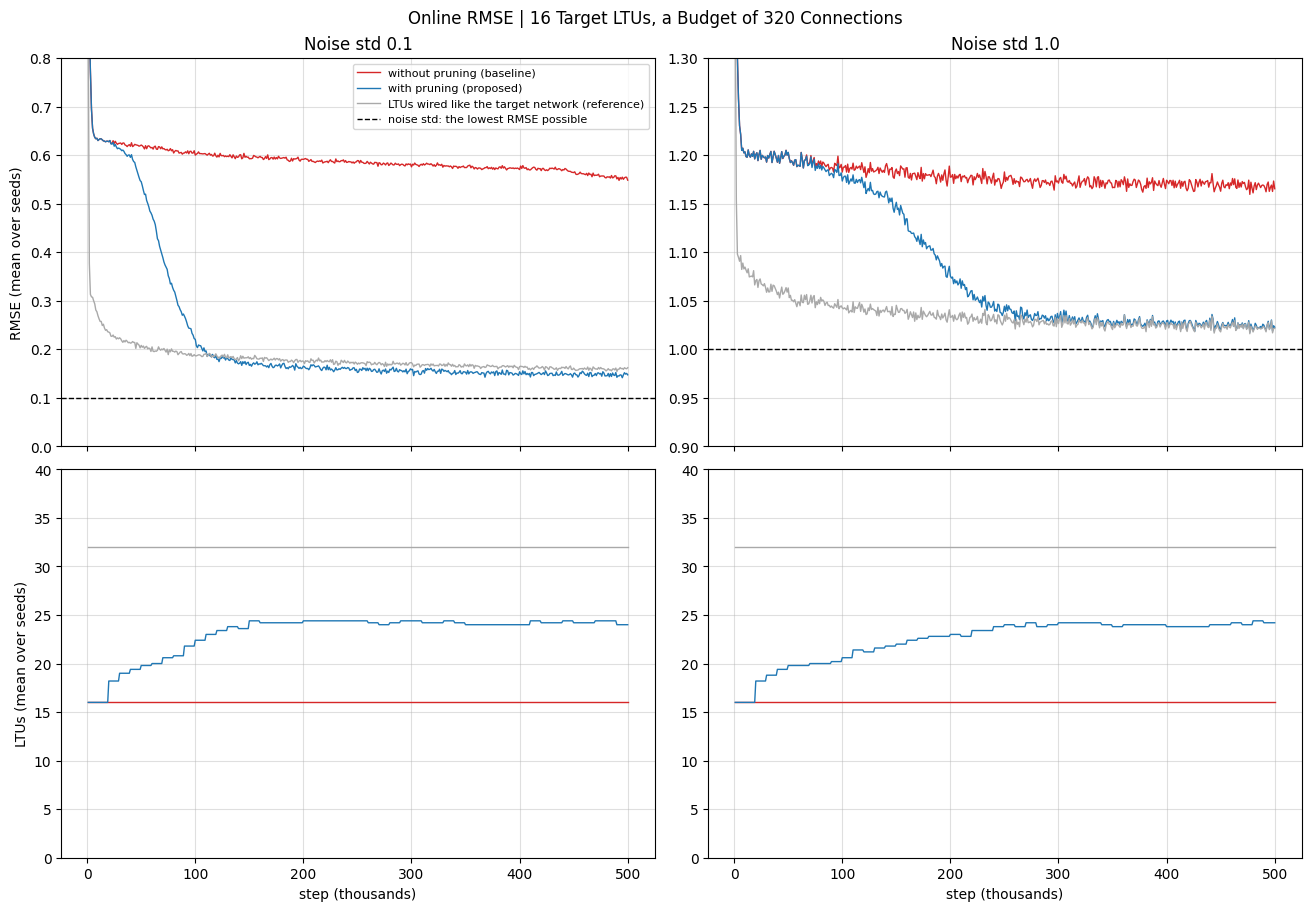

noise 0.1, RMSE over the last 100k steps: without pruning 0.564, with pruning 0.149, LTUs wired like the target network 0.160
noise 1.0, RMSE over the last 100k steps: without pruning 1.169, with pruning 1.025, LTUs wired like the target network 1.023


In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
CURVES = [('without pruning (baseline)', KEPT, 'tab:red'), ('with pruning (proposed)', PRUNED, 'tab:blue'),
          ('LTUs wired like the target network (reference)', REFERENCE, 'darkgray')]

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, layout='constrained')
for column, (noise, ylim) in enumerate(zip(NOISE_STDS, [(0, 0.8), (0.9, 1.3)])):
    for label, config, color in CURVES:
        axes[0, column].plot(STEPS / 1000, rmse[config, noise].mean(0), color=color, lw=1, label=label)
        axes[1, column].plot(STEPS / 1000, ltus[config, noise].mean(0), color=color, lw=1, label=label)
    axes[0, column].axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
    axes[0, column].set(title=f'Noise std {noise}', ylim=ylim)
    axes[1, column].set(xlabel='step (thousands)', ylim=(0, 40))
for ax in axes.flat:
    ax.grid(alpha=0.4)
axes[0, 0].legend(fontsize=8)
axes[0, 0].set_ylabel('RMSE (mean over seeds)')
axes[1, 0].set_ylabel('LTUs (mean over seeds)')
fig.suptitle(f'Online RMSE | {N_TARGETS} Target LTUs, a Budget of {BUDGET} Connections')
plt.show()

last = 100_000 // WINDOW
for noise in NOISE_STDS:
    print(f'noise {noise}, RMSE over the last 100k steps: '
          + ', '.join(f'{label.split(" (")[0]} {rmse[config, noise][:, -last:].mean():.3f}' for label, config, _ in CURVES))

## Results

Without pruning, the LTUs' first inputs fill the budget, leaving no room to grow or to add LTUs, and the method learns
little. With pruning, the same budget holds about 24 LTUs, and the method ends about level with LTUs wired like the
target network, at both noise levels.

## Details

**Target.** Each of 16 target LTUs reads 10 of 1000 standard normal inputs with weights $\pm 1$, and each of the 10
outputs reads 4 of them with weights $\pm 1/2$, plus noise of std 0.1 or 1, the lowest RMSE possible.

**Budget.** 320 connections from the inputs to the LTUs (biases not counted): room for 2 LTUs wired like each target
LTU, which is the reference. The method starts with as many LTUs as fit at 20 inputs each, 16, reading random inputs
with random signs. Growth connects an input only while the budget has room. Every 10k steps, after pruning, search
removes the 4 LTUs with the smallest sum of |output weights|, then adds new LTUs, each reading 20 inputs drawn by its
parent's weights, as long as the budget has room for them. The budget is the problem's; the method adds no
hyperparameter. At most 48 LTUs fit in memory, more than the method ever holds.

**More LTUs, not only room to grow.** With pruning, but search adding no more LTUs than it removes, the method keeps
16 LTUs and uses about 200 of the 320 connections. It ends at RMSE 0.24 at noise 0.1 and 1.05 at noise 1, against 0.15
and 1.02 when search fills the budget (checked separately, 5 seeds).

**Target weights $N(0, 1)$.** Cutting on sign changes could cut right inputs whose target weights are small, as their
learned weights are small too. With the target LTUs' weights drawn $N(0, 1)$, the method with pruning still ends at
RMSE 0.15 at noise 0.1 and 1.02 at noise 1, level with the reference's 0.16 and 1.02, and without pruning at 0.44 and
1.13 (checked separately, 5 seeds).